In [1]:
import numpy as np
import os
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
from jfunctions import *

base_dir = '/data/phh1-hosted/cwp29/mpas-a/scaling/'

qu_240 = 'x1.10242'
qu_120 = 'x1.40962'
qu_60 = 'x1.163842'
qu_30 = 'x1.655362'
qu_15 = 'x1.2621442'

log_file = 'log.atmosphere.0000.out'
#log_loc = '/data/phh1-hosted/cwp29/mpas-a/control/log.atmosphere.0000.out'

%matplotlib widget

In [2]:
def get_times(log_loc, indicator_string):
    ts = []
    
    with open(log_loc) as f:
        for l in f.readlines():
            if indicator_string in l:
                try:
                    time = float(l.split(': ')[1].split(' ')[0])
                    ts.append(time)
                except:
                    pass
    
    return np.array(ts)

8 7.434558916666666 cold_start
16 3.68122925 cold_start
24 2.5023067500000002 cold_start
36 1.6868282916666668 cold_start
48 1.2718944749999999 cold_start
64 0.95730025 cold_start
96 0.6526982583333333 cold_start
128 0.5335897333333333 cold_start
8 9.323476000000001 steady
16 4.719379333333333 steady
24 3.1711656666666665 steady
36 2.127477333333333 steady
48 1.629574466666667 steady
64 1.2650545333333334 steady
96 0.8422749666666669 steady
128 0.6655974666666667 steady


Text(0, 0.5, 'timestep')

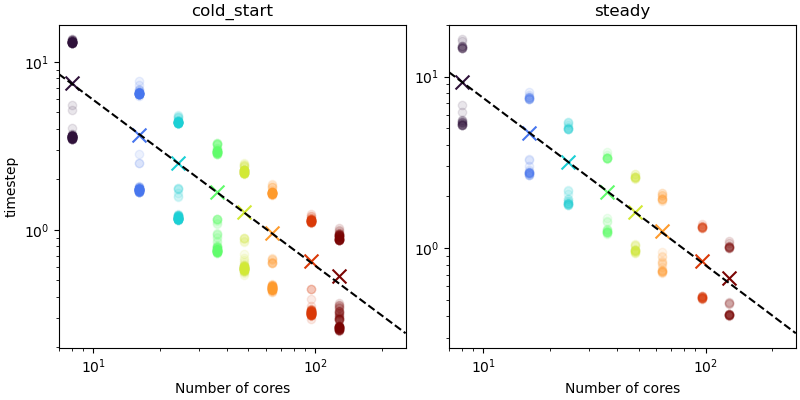

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

grid_name = qu_120
core_list = [8, 16, 24, 36, 48, 64, 96, 128]
cols = plt.cm.turbo(np.linspace(0, 1, len(core_list)))

f = lambda x, a, b: b*np.power(x, a)

for i, label in enumerate(['cold_start', 'steady']):
    dt_list = []

    for cores, c in zip(core_list, cols):
            if label == 'cold_start':
                path = os.path.join(base_dir, 'cores', label, grid_name, str(cores))
            else:
                path = os.path.join(base_dir, 'cores', label, str(cores))
            
            dts = get_times(os.path.join(path, log_file), 'Timing for integration step')
            dt_list.append(np.mean(dts))
            Ncells = float(grid_name.split('.')[1])
        
            print(cores, np.mean(dts), label)
        
            ax[i].scatter(cores, np.mean(dts), color=c, label=cores, marker='x', s=100)
            ax[i].scatter([[cores]*len(dts)], dts, color=c, label=cores, alpha=0.1)
            #ax[i].errorbar(cores, np.mean(dts), yerr=np.std(dts), color=c)

            ax[i].set_title(label)
            ax[i].set_yscale('log')
            ax[i].set_xscale('log')
        
            ax[i].set_xlabel('Number of cores')
        
    popt_cores, _ = curve_fit(f, core_list, dt_list)
    xs = np.arange(7, 256, 1)
    ax[i].plot(xs, [f(x, *popt_cores) for x in xs], color='k', ls='--')
    ax[i].set_xlim(xs[0], xs[-1])

ax[0].set_ylabel('timestep')

CSD3 test:  1.6707347750000001
Swirles, qu_15km grid:  11.297276010416669
CSD3, qu_15km grid:  14.585283333333335
CSD3, tr_15km grid:  8.410707815104166


NameError: name 'scale_estimate' is not defined

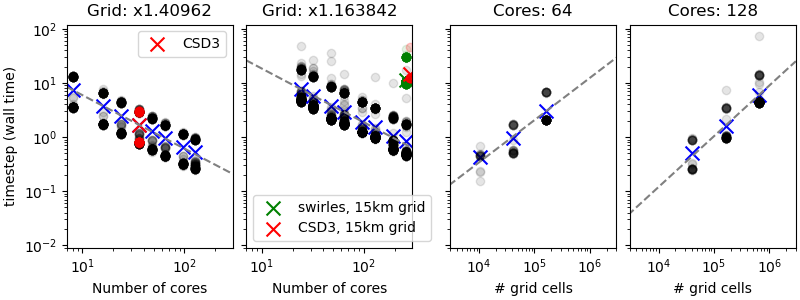

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(8, 3), constrained_layout=True, sharey=True)

grid_name = qu_120
core_list = {
    'x1.40962': [8, 16, 24, 36, 48, 64, 96, 128],
    'x1.163842': [24, 32, 48, 64, 96, 128, 192, 256]
}

f = lambda x, a, b: b*np.power(x, a)

cols = plt.cm.turbo(np.linspace(0, 1, len(core_list['x1.163842'])))

for i, label in enumerate(['x1.40962', 'x1.163842']):
    dt_list = []

    for cores, c in zip(core_list[label], cols):
            path = os.path.join(base_dir, 'cores', 'cold_start', label, str(cores))
            
            dts = get_times(os.path.join(path, log_file), 'Timing for integration step')
            dt_list.append(np.mean(dts))
            Ncells = float(grid_name.split('.')[1])
        
            ax[i].scatter(cores, np.mean(dts), color='b', marker='x', s=100)
            ax[i].scatter([[cores]*len(dts)], dts, color='k', alpha=0.1)

            ax[i].set_title('Grid: %s'%label)
            ax[i].set_yscale('log')
            ax[i].set_xscale('log')
        
            ax[i].set_xlabel('Number of cores')

    popt_cores, _ = curve_fit(f, core_list[label], dt_list)
    xs = np.arange(7, 300, 1)
    ax[i].plot(xs, [f(x, *popt_cores) for x in xs], color='gray', ls='--')
    ax[i].set_xlim(xs[0], xs[-1])

ax[0].set_ylabel('timestep (wall time)')

core_grids = {
    64 : [qu_240, qu_120, qu_60],
    128: [qu_120, qu_60, qu_30]
}

for i, cores in enumerate([64, 128]):
    ncells_list = []
    dt_list = []
    diag_list = []
    hist_list = []
    
    for grid_name in core_grids[cores]:
        path = os.path.join(base_dir, 'grid', '%s'%cores, grid_name)
        dts = get_times(os.path.join(path, log_file), 'Timing for integration step')
        dt_list.append(np.mean(dts))
        ncells = float(grid_name.split('.')[1])
        ncells_list.append(ncells)

        ax[i+2].scatter(ncells, np.mean(dts), color='b', marker='x', s=100)
            
        ax[i+2].scatter([[ncells]*len(dts)], dts, color='k', alpha=0.1)

    ax[i+2].set_title("Cores: %s"%cores)
        
    popt_cells, _ = curve_fit(f, ncells_list, dt_list)
    xs = np.arange(1000, 10000000, 1000)
    ax[i+2].plot(xs, [f(x, *popt_cells) for x in xs], color='gray', ls='--')
    ax[i+2].set_xlim(3e3, 3e6)
    
ax[2].set_xlabel('# grid cells')
ax[3].set_xlabel('# grid cells')

for a in ax:
    a.set_yscale('log')
    a.set_xscale('log')

# Additional estimates...
# CSD3, x1.40962, 36 cores
dts = get_times(os.path.join(base_dir, 'cores', 'cold_start', 'x1.40962', 'csd3_36', log_file), 'Timing for integration step')
print('CSD3 test: ', np.mean(dts))
ax[0].scatter(36, np.mean(dts), marker='x', s=100, color='r', label="CSD3")
ax[0].scatter([[36]*len(dts)], dts, alpha=0.1, color='r')
ax[0].legend()

# swirles, x1.2621442, 256 cores
dts = get_times(os.path.join(base_dir, 'grid', '256', 'x1.2621442', 'swirles', log_file), 'Timing for integration step')
print('Swirles, qu_15km grid: ', np.mean(dts))
#print(scale_estimate(256, 2621442, 1, 18)[0])
ax[1].scatter(256, np.mean(dts), marker='x', s=100, color='g', label="swirles, 15km grid")
#ax[1].scatter(256, scale_estimate(256, 2621442, 1, 18)[0], marker='^', s=100, color='g')
ax[1].scatter([[256]*len(dts)], dts, alpha=0.1, color='g')

# CSD3, x1.2621442, 256 cores
dts = get_times(os.path.join(base_dir, 'grid', '256', 'x1.2621442', 'csd3', log_file), 'Timing for integration step')
print('CSD3, qu_15km grid: ', np.mean(dts))
ax[1].scatter(280, np.mean(dts), marker='x', s=100, color='r', label="CSD3, 15km grid")
ax[1].scatter([[280]*len(dts)], dts, alpha=0.1, color='r')
ax[1].legend()

# CSD3, tr_60_15, 224 cores
dts = get_times(os.path.join(base_dir, 'tr_test', log_file), 'Timing for integration step')
print('CSD3, tr_15km grid: ', np.mean(dts))
print(scale_estimate(224, 1572866, 1, 18)[0])
ax[1].scatter(224, np.mean(dts), marker='x', s=100, color='purple', label="CSD3, tr_15km grid")
ax[1].scatter([[224]*len(dts)], dts, alpha=0.1, color='purple')
ax[1].legend()

#save_fig(fig, '/home/cwp29/tmp/mpas/scaling.png', dpi=300)

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(8, 3), constrained_layout=True, sharey=True)

grid_name = qu_120
core_list = {
    'x1.40962': [8, 16, 24, 36, 48, 64, 96, 128],
    'x1.163842': [24, 32, 48, 64, 96, 128, 192, 256]
}

f = lambda x, a, b: b*np.power(x, a)

cols = plt.cm.turbo(np.linspace(0, 1, len(core_list['x1.163842'])))

for i, label in enumerate(['x1.40962', 'x1.163842']):
    dt_list = []

    for cores, c in zip(core_list[label], cols):
            path = os.path.join(base_dir, 'cores', 'cold_start', label, str(cores))
            
            dts = get_times(os.path.join(path, log_file), 'Timing for stream output')
            print(dts)
            dt_list.append(np.mean(dts))
            Ncells = float(grid_name.split('.')[1])
        
            ax[i].scatter(cores, np.mean(dts), color='b', marker='x', s=100)
            ax[i].scatter([[cores]*len(dts)], dts, color='k', alpha=0.1)

            ax[i].set_title('Grid: %s'%label)
            ax[i].set_yscale('log')
            ax[i].set_xscale('log')
        
            ax[i].set_xlabel('Number of cores')

    popt_cores, _ = curve_fit(f, core_list[label], dt_list)
    xs = np.arange(7, 300, 1)
    ax[i].plot(xs, [f(x, *popt_cores) for x in xs], color='gray', ls='--')
    ax[i].set_xlim(xs[0], xs[-1])

ax[0].set_ylabel('timestep (wall time)')

core_grids = {
    64 : [qu_240, qu_120, qu_60],
    128: [qu_120, qu_60, qu_30]
}

for i, cores in enumerate([64, 128]):
    ncells_list = []
    dt_list = []
    diag_list = []
    hist_list = []
    
    for grid_name in core_grids[cores]:
        path = os.path.join(base_dir, 'grid', '%s'%cores, grid_name)
        dts = get_times(os.path.join(path, log_file), 'Timing for stream output')
        dt_list.append(np.mean(dts))
        ncells = float(grid_name.split('.')[1])
        ncells_list.append(ncells)

        ax[i+2].scatter(ncells, np.mean(dts), color='b', marker='x', s=100)
            
        ax[i+2].scatter([[ncells]*len(dts)], dts, color='k', alpha=0.1)

    ax[i+2].set_title("Cores: %s"%cores)
        
    popt_cells, _ = curve_fit(f, ncells_list, dt_list)
    xs = np.arange(1000, 10000000, 1000)
    ax[i+2].plot(xs, [f(x, *popt_cells) for x in xs], color='gray', ls='--')
    ax[i+2].set_xlim(3e3, 3e6)
    
ax[2].set_xlabel('# grid cells')
ax[3].set_xlabel('# grid cells')

for a in ax:
    a.set_yscale('log')
    a.set_xscale('log')

# Additional estimates...
# CSD3, x1.40962, 36 cores
dts = get_times(os.path.join(base_dir, 'cores', 'cold_start', 'x1.40962', 'csd3_36', log_file), 'Timing for stream output')
print('CSD3 test: ', np.mean(dts))
ax[0].scatter(36, np.mean(dts), marker='x', s=100, color='r', label="CSD3")
ax[0].scatter([[36]*len(dts)], dts, alpha=0.1, color='r')
ax[0].legend()

# swirles, x1.2621442, 256 cores
dts = get_times(os.path.join(base_dir, 'grid', '256', 'x1.2621442', 'swirles', log_file), 'Timing for stream output')
print('Swirles, qu_15km grid: ', np.mean(dts))
ax[1].scatter(256, np.mean(dts), marker='x', s=100, color='g', label="swirles, 15km grid")
ax[1].scatter([[256]*len(dts)], dts, alpha=0.1, color='g')

# CSD3, x1.2621442, 256 cores
dts = get_times(os.path.join(base_dir, 'grid', '256', 'x1.2621442', 'csd3', log_file), 'Timing for stream output')
print('CSD3, qu_15km grid: ', np.mean(dts))
ax[1].scatter(256, np.mean(dts), marker='x', s=100, color='r', label="CSD3, 15km grid")
ax[1].scatter([[256]*len(dts)], dts, alpha=0.1, color='r')
ax[1].legend()

# swirles(?), tr_60_15, 256(?) cores

#save_fig(fig, '/home/cwp29/tmp/mpas/scaling.png', dpi=300)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

core_grids = {
    64 : [qu_240, qu_120, qu_60],
    128: [qu_120, qu_60, qu_30]
}

for cores, c in zip([64, 128], ['b', 'r']):
    ncells_list = []
    dt_list = []
    diag_list = []
    hist_list = []
    
    for grid_name in core_grids[cores]:
        path = os.path.join(base_dir, 'grid', '%s'%cores, grid_name)
        dts = get_times(os.path.join(path, log_file), 'Timing for integration step')
        dt_list.append(np.mean(dts))
        ncells = float(grid_name.split('.')[1])
        ncells_list.append(ncells)
        
        diag_size = os.path.getsize(os.path.join(path, 'diag.2000-03-01_06.00.00.nc'))
        hist_size = os.path.getsize(os.path.join(path, 'history.2000-03-01_06.00.00.nc'))
        diag_list.append(diag_size/(1024**3))
        hist_list.append(hist_size/(1024**3))
    
        ax[0].scatter(ncells, np.mean(dts), color=c, label=cores, marker='x', s=100)
        ax[0].scatter([[ncells]*len(dts)], dts, color=c, label=cores, alpha=0.1)
        #ax[0].errorbar(ncells, np.mean(dts), yerr=np.std(dts), color=c)
        ax[0].set_ylabel('time step (s)')

        print(ncells, cores, np.mean(dts), len(dts), 6*60*60/len(dts))

        ax[1].scatter(ncells, diag_size/(1024 * 1024 * 1024), color=c)
        ax[1].scatter(ncells, hist_size/(1024 * 1024 * 1024), color=c, marker='s')
        ax[1].set_ylabel('output file size (GiB)')
        
    popt_cells, _ = curve_fit(f, ncells_list, dt_list)
    xs = np.arange(10000, 1000000, 1000)
    ax[0].plot(xs, [f(x, *popt_cells) for x in xs], color='k', ls='--')
    
    popt, _ = curve_fit(f, ncells_list, diag_list)
    print(popt)
    ax[1].plot(xs, [f(x, *popt) for x in xs], color='k', ls='--')
    
    popt, _ = curve_fit(f, ncells_list, hist_list)
    print(popt)
    ax[1].plot(xs, [f(x, *popt) for x in xs], color='k', ls='-.')
    
ax[0].set_title('Timestep duration vs. grid size')
ax[1].set_title('File size vs. grid size')

for a in ax:
    a.set_yscale('log')
    a.set_xscale('log')
    a.set_xlabel('# grid cells')

In [6]:
# Estimate

sim_length = 200 # days

ref_cores = 128
ref_cells = 163842
print(f(ref_cells, *popt_cells))
print(f(ref_cores, *popt_cores))
ref_dt = 0.51

target_cores = 2240
target_cells = 29622274
target_step = 18

# Esimate 1

est_cell_dt = f(target_cells, *popt_cells)
est_cores_dt = f(ref_cores, *popt_cores)

est_dt = (est_cell_dt / est_cores_dt) * f(target_cores, *popt_cores)
print(est_dt)
print(est_dt * target_cores * (sim_length * 24 * 60 * 60 / target_step) / (60 * 60) / 1e6)

print("###################")
# Estimate 2
est_cores_dt = f(target_cores, *popt_cores)
est_cells_dt = f(ref_cells, *popt_cells)

est_dt = (est_cores_dt / est_cells_dt) * f(target_cells, *popt_cells)
print(est_dt)
print(est_dt * target_cores * (sim_length * 24 * 60 * 60 / target_step) / (60 * 60) / 1e6)

1.6466650327264345
1.4613903501281784
12.592490835212764
7.521914525567091
###################
11.175645456069347
6.6755855524254235


In [5]:
# Estimate

def scale_estimate(target_cores, target_cells, sim_length, target_step):
    #sim_length = 200 # days
    
    ref_cores = 128
    ref_cells = 40962
    ref_dt = 0.51
    
    #target_cores = 1152
    #target_cells = 29622274
    #target_step = 18
    
    # Esimate 1
    
    est_cell_dt = f(target_cells, *popt_cells)
    est_cores_dt = f(ref_cores, *popt_cores)
    
    est_dt1 = (est_cell_dt / est_cores_dt) * f(target_cores, *popt_cores)
    cpuh1 = est_dt1 * target_cores * (sim_length * 24 * 60 * 60 / target_step) / (60 * 60) / 1e6
    
    # Estimate 2
    est_cores_dt = f(target_cores, *popt_cores)
    est_cells_dt = f(ref_cells, *popt_cells)
    
    est_dt2 = (est_cores_dt / est_cells_dt) * f(target_cells, *popt_cells)
    cpuh2 = est_dt2 * target_cores * (sim_length * 24 * 60 * 60 / target_step) / (60 * 60) / 1e6

    return est_dt1, est_dt2, cpuh1, cpuh2


for cores in [64, 128, 256]:
    print(scale_estimate(cores, 2500000, 30, 18))


(42.340006014695525, 138.05666195512606, 0.10839041539762054, 0.3534250546051227)
(21.26100254344706, 69.32505016529707, 0.10885633302244895, 0.354944256846321)
(10.676196621124001, 34.81152240217921, 0.10932425340030977, 0.3564699893983151)


In [ ]:
# Estimate

ref_cores = 128
ref_cells = 40962
ref_dt = 0.51

target_cores = 128
target_cells = 1572866

# Esimate 1

est_cell_dt = f(target_cells, *popt_cells)
est_cores_dt = f(ref_cores, *popt_cores)

est_dt = (est_cell_dt / est_cores_dt) * f(target_cores, *popt_cores)
print(est_dt)

print("###################")
# Estimate 2
est_cores_dt = f(target_cores, *popt_cores)
est_cells_dt = f(ref_cells, *popt_cells)

est_dt = (est_cores_dt / est_cells_dt) * f(target_cells, *popt_cells)
print(est_dt)

In [24]:
# Swirles TR estimates
ref_cores = 128
ref_cells = 163842

target_cores = 256
target_cells = 1000000
mem_per_core = 0.25 * target_cells / target_cores

est_cell_dt = f(target_cells, *popt_cells)
est_cores_dt = f(ref_cores, *popt_cores)

est_dt = (est_cell_dt / est_cores_dt) * f(target_cores, *popt_cores)

sim_days = 40 # spin-up
sim_days += 3*200 # analysis
sim_dt = 5 * 6

print("Estimated wall-time per timestep: {0:.3f} seconds".format(est_dt))
print("Total simulation run time: {0:.1f} days".format(est_dt * sim_days / sim_dt))
print("Memory requirements per core: {0:.2f} GiB".format(mem_per_core/1024))
print("Estimated output file size: {0:.2f} GiB".format(4.5e-6 * target_cells))

Estimated wall-time per timestep: 4.517 seconds
Total simulation run time: 96.4 days
Memory requirements per core: 0.95 GiB
Estimated output file size: 4.50 GiB
